MOBILE PRICE DATASET
   Battery_Power  RAM  Internal_Memory  Camera  Screen_Size  Processor_Speed  \
0           1860    4               32      77     4.655508         3.077373   
1           4772    9              256      89     4.868258         1.299728   
2           4092   10               64      92     4.519604         2.837315   
3           1466   11              128     102     6.077304         2.328637   
4           5426    6              256      90     5.619184         1.719863   

   Weight  Battery_Life  Price_Range  
0     166            20            2  
1     170             5            3  
2     245            20            3  
3     205             9            3  
4     106             7            3  

Price Range Distribution:
Price_Range
1     35
2    324
3    641
Name: count, dtype: int64

Model Training Completed Successfully!

Predicted Price Ranges:
[2 2 3 3 2 3 3 2 3 1]

Actual Price Ranges:
[1 3 3 3 3 3 3 2 2 1]

Model Accuracy: 87.50%

CLASSIFICATION R

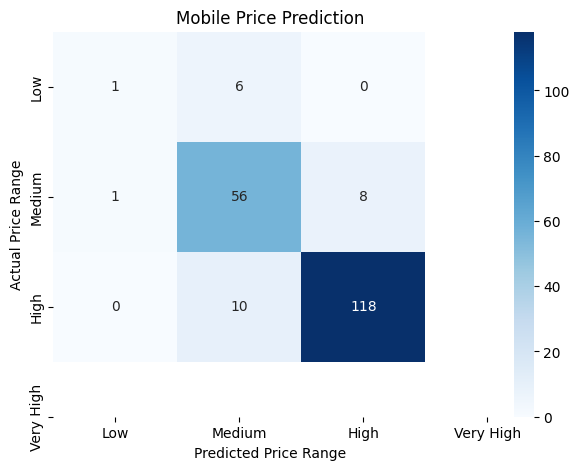


NEW MOBILE DETAILS
   Battery_Power  RAM  Internal_Memory  Camera  Screen_Size  Processor_Speed  \
0           5000    8              128      64          6.5              2.8   

   Weight  Battery_Life  
0     180            18  

Predicted Mobile Price Range: Very High Price


In [7]:

# MOBILE PRICE PREDICTION USING RANDOM FOREST CLASSIFICATION

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Step 2: Generate a sample mobile dataset
np.random.seed(42)

n = 1000

data = pd.DataFrame({
    'Battery_Power': np.random.randint(1000, 6000, n),
    'RAM': np.random.randint(1, 13, n),
    'Internal_Memory': np.random.choice(
        [16, 32, 64, 128, 256, 512], n
    ),
    'Camera': np.random.randint(5, 108, n),
    'Screen_Size': np.random.uniform(4.5, 7.0, n),
    'Processor_Speed': np.random.uniform(1.0, 3.5, n),
    'Weight': np.random.randint(100, 250, n),
    'Battery_Life': np.random.randint(5, 25, n)
})

# Step 3: Generate mobile price ranges
price = (
    data['Battery_Power'] * 5
    + data['RAM'] * 15000
    + data['Internal_Memory'] * 300
    + data['Camera'] * 1000
    + data['Screen_Size'] * 10000
    + data['Processor_Speed'] * 20000
    + data['Battery_Life'] * 2000
    - data['Weight'] * 100
)

# Step 4: Convert prices into price categories
data['Price_Range'] = pd.cut(
    price,
    bins=[-np.inf, 100000, 200000, 300000, np.inf],
    labels=[0, 1, 2, 3]
).astype(int)

print("MOBILE PRICE DATASET")
print(data.head())

# Step 5: Separate input and output variables
X = data.drop('Price_Range', axis=1)
y = data['Price_Range']

print("\nPrice Range Distribution:")
print(y.value_counts().sort_index())

# Step 6: Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 7: Create Random Forest Classifier
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Step 8: Train the model
model.fit(X_train, y_train)

print("\nModel Training Completed Successfully!")

# Step 9: Predict mobile price ranges
y_pred = model.predict(X_test)

print("\nPredicted Price Ranges:")
print(y_pred[:10])

print("\nActual Price Ranges:")
print(y_test.iloc[:10].values)

# Step 10: Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy: {:.2f}%".format(accuracy * 100))

# Step 11: Display classification report
print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# Step 12: Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nCONFUSION MATRIX")
print(cm)

# Step 13: Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[
        'Low', 'Medium', 'High', 'Very High'
    ],
    yticklabels=[
        'Low', 'Medium', 'High', 'Very High'
    ]
)

plt.xlabel("Predicted Price Range")
plt.ylabel("Actual Price Range")
plt.title("Mobile Price Prediction")
plt.show()

# Step 14: Predict price range of a new mobile
new_mobile = pd.DataFrame([{
    'Battery_Power': 5000,
    'RAM': 8,
    'Internal_Memory': 128,
    'Camera': 64,
    'Screen_Size': 6.5,
    'Processor_Speed': 2.8,
    'Weight': 180,
    'Battery_Life': 18
}])

prediction = model.predict(new_mobile)

price_categories = {
    0: 'Low Price',
    1: 'Medium Price',
    2: 'High Price',
    3: 'Very High Price'
}

print("\nNEW MOBILE DETAILS")
print(new_mobile)

print("\nPredicted Mobile Price Range:",
      price_categories[prediction[0]])
